In [1]:
import numpy as np
import pandas as pd
import spacy

In [2]:
#Read your train and test set
data = pd.read_csv('./train_tickets.csv')

In [ ]:
# train.drop("Unnamed: 0",axis=1 ,inplace=True)
# test.drop("Unnamed: 0",axis=1 ,inplace=True)

In [4]:
#Get the specific data as informed bellow
X_train = data['description']
y_train = data['about']

X_test = data['description']
y_test = data['about']

In [5]:
nlp = spacy.load('en_core_web_sm', disable = ['tagger','parser','ner'])

In [6]:
#Create a function to transform tickets in tokens
def transform_tickets(tickets):
    tickets = tickets.apply(lambda x: nlp(x))
    tickets = tickets.apply(lambda x: [token.lemma_ for token in x if not token.is_stop and not token.is_punct])
    tickets = tickets.apply(lambda x: ' '.join(x))
    return tickets

In [15]:
from tqdm import tqdm

clean_train_tickets = []

for ticket in tqdm(X_train):
    clean_train_tickets.append(transform_tickets(pd.Series([ticket])).iloc[0])
 

  0%|          | 0/135 [00:00<?, ?it/s]c:\Users\renzo\OneDrive\Belgeler\GitHub\AI-frameworks-\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
c:\Users\renzo\OneDrive\Belgeler\GitHub\AI-frameworks-\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
c:\Users\renzo\OneDrive\Belgeler\GitHub\AI-frameworks-\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your 

In [16]:
clean_train_tickets

['rgb mode stuck lightsaber hmm problem installing latest security update broken lightsaber longer stable blade rgb mode displays red blue green flashing endlessly balance disco use battle impossible   jedi tool toy fix',
 'broken pc hey thursday pc fell floor wanted know procedure require new sorry inconvenience thanks advance',
 'ergonomic chair purchase running low ergonomic chairs office   order additional ergonomic chairs improve employee comfort',
 'privacy glass windows nice privacy glasses windows corporate building working street glass wall makes feel uncomfortable',
 'request updated design software license current license design application appears expired preventing file export collaboration kindly initiate renewal process assign active license',
 'cuda cpu use wo work ai training want use gpu check requirements met cuda',
 'replacement malfunctioning input device current keyboard intermittently fails register keystrokes significantly slowing report preparation appreciate r

In [18]:
from sklearn.feature_extraction.text import CountVectorizer

#Create a CountVectorizer object 
vectorizer = CountVectorizer()
X_train_vectorized = vectorizer.fit_transform(clean_train_tickets)


In [19]:
vocab = vectorizer.get_feature_names_out()
print(vocab)

['02' '10' '12' ... 'year' 'years' 'yesterday']


In [21]:

X_train_vectorized[0].toarray()


array([[0, 0, 0, ..., 0, 0, 0]], shape=(1, 1154))

In [22]:
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()

classifier.fit(X_train_vectorized, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[45.,37.,53.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.1 ,-1.29,-0.93]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U20](3,)","['Privacy issue','Purchase requisition','Software issue']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 1154)","[[1.,1.,2.,...,0.,1.,1.], [0.,1.,0.,...,1.,0.,0.], [0.,1.,2.,...,0.,0.,1.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 1154)","[[-6.91,-6.91,-6.51,...,-7.61,-6.91,-6.91], [-7.55,-6.86,-7.55,...,-6.86,-7.55,-7.55], [-7.66,-6.97,-6.57,...,-7.66,-7.66,-6.97]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1154


Preprocess and transform the test set!

In [23]:
clean_test_reviews = []

#perform the data processing in our test set 
for ticket in tqdm(X_test):
    clean_test_reviews.append(transform_tickets(pd.Series([ticket])).iloc[0])

  0%|          | 0/135 [00:00<?, ?it/s]c:\Users\renzo\OneDrive\Belgeler\GitHub\AI-frameworks-\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
c:\Users\renzo\OneDrive\Belgeler\GitHub\AI-frameworks-\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
c:\Users\renzo\OneDrive\Belgeler\GitHub\AI-frameworks-\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your 

In [ ]:
clean_test_reviews

In [24]:
test_data_features = vectorizer.transform(clean_test_reviews)

Check your score

In [26]:
#check the score

score = classifier.score(test_data_features, y_test)
print(score)

1.0


Look at your results and compare with your ground truth

In [28]:
#check the prediction
y_pred = classifier.predict(test_data_features)
print(y_pred)

['Software issue' 'Purchase requisition' 'Purchase requisition'
 'Privacy issue' 'Software issue' 'Software issue' 'Software issue'
 'Software issue' 'Privacy issue' 'Software issue' 'Purchase requisition'
 'Software issue' 'Software issue' 'Software issue' 'Purchase requisition'
 'Privacy issue' 'Privacy issue' 'Purchase requisition' 'Software issue'
 'Software issue' 'Purchase requisition' 'Privacy issue' 'Privacy issue'
 'Purchase requisition' 'Software issue' 'Purchase requisition'
 'Privacy issue' 'Purchase requisition' 'Purchase requisition'
 'Purchase requisition' 'Purchase requisition' 'Privacy issue'
 'Software issue' 'Privacy issue' 'Software issue' 'Purchase requisition'
 'Software issue' 'Privacy issue' 'Software issue' 'Software issue'
 'Purchase requisition' 'Software issue' 'Privacy issue'
 'Purchase requisition' 'Purchase requisition' 'Purchase requisition'
 'Purchase requisition' 'Privacy issue' 'Privacy issue' 'Software issue'
 'Software issue' 'Purchase requisition' 

In [32]:
y_test

array(['Software issue', 'Purchase requisition', 'Purchase requisition',
       'Privacy issue', 'Software issue', 'Software issue',
       'Software issue', 'Software issue', 'Privacy issue',
       'Software issue', 'Purchase requisition', 'Software issue',
       'Software issue', 'Software issue', 'Purchase requisition',
       'Privacy issue', 'Privacy issue', 'Purchase requisition',
       'Software issue', 'Software issue', 'Purchase requisition',
       'Privacy issue', 'Privacy issue', 'Purchase requisition',
       'Software issue', 'Purchase requisition', 'Privacy issue',
       'Purchase requisition', 'Purchase requisition',
       'Purchase requisition', 'Purchase requisition', 'Privacy issue',
       'Software issue', 'Privacy issue', 'Software issue',
       'Purchase requisition', 'Software issue', 'Privacy issue',
       'Software issue', 'Software issue', 'Purchase requisition',
       'Software issue', 'Privacy issue', 'Purchase requisition',
       'Purchase requisi

Plot a confusion matrix

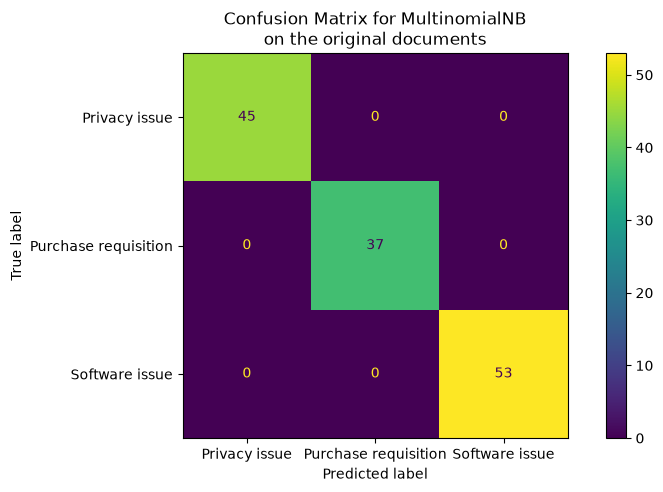

In [34]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

target_names = ['Privacy issue', 'Purchase requisition', 'Software issue']

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax)
ax.xaxis.set_ticklabels(target_names)
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(f"Confusion Matrix for {classifier.__class__.__name__}\non the original documents")

**Not bad, right?**

Now is your time to play!


---> we use 5000 features, which can consist of unigrams (single words) or bigrams, when using the code below:

vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 5000,
                             ngram_range=(1,2))


What you should do:
- Try to check another parameters, another combination and train your naive bayes model

### Next

Apply other models:
- LogisticRegression
- BernoulliNB
- DecisionTreeClassifier



**Question:** Would you try a Neural Network in this data? Explain your thoughts.